# 2. Phase diagram

Where does the economy keep fluctuating, and where does the mean firm grow? First the deterministic model
(immigration floor $\lambda$, here mostly $\lambda=0$), solved by heterogeneous dynamical mean-field theory
(HDMFT); then demographic noise, where an exact renewal law for one node replaces the clipped Gaussian.

Paper sign throughout the text: $\mu<0$ is competition. The code uses the opposite sign (`mu=1.76`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq, fsolve
from scipy.integrate import quad, cumulative_trapezoid
from economy import powerlaw_coupling, configuration_coupling, integrate_demographic, DATA, FIGURES, tidy

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})
w0, phi = norm.cdf, norm.pdf
w1 = lambda d: d * norm.cdf(d) + norm.pdf(d)
w2 = lambda d: (1 + d * d) * norm.cdf(d) + d * norm.pdf(d)


def degrees(alpha, N=4000, C=100, seed=0):
    """Degree sequence of the phase-grid graphs (networkx configuration model, collapsed to a simple graph)."""
    return np.diff(powerlaw_coupling(N, 0.0, 1.0, alpha=alpha, mean_degree=C, seed=seed).indptr).astype(float)


def classes(k, n_bins=60):
    """Degree classes and the soft-configuration kernel (structural cutoff of a simple graph)."""
    cl = bin_degree_distribution(k, n_bins=n_bins)
    K = soft_configuration_kernel(cl["degree_fractions"], cl["weights"], cl["connectance"])["kernel"]
    return cl["weights"], K, cl["connectance"], cl

## Heterogeneous mean-field theory

Group the nodes into degree classes $p$ with fractions $\rho_p$, and let $P_{pr}$ be the probability that a node
of class $p$ links to one of class $r$. The uncorrelated choice $P_{pr}=k_pk_r/(NC)$ exceeds one for pairs of
hubs at $\alpha=2.5$ (the structural cutoff of a simple graph); we use the soft-configuration kernel
$P_{pr}=h_ph_r/(h_ph_r+C/N)$ with hidden degrees fixed by the degree constraint (Patil, Altieri &
Aguirre-López 2026), and write $K_{pr}=N\rho_rP_{pr}/C$.

For $C\to\infty$ the mean part of the interaction field on a node of class $p$ tends to $\mu B_p$ and, by the
dynamical cavity argument, the random part to a Gaussian process of covariance $\sigma^2q_p(t,t')$:

$$B_p(t)=\sum_rK_{pr}\,\mathbb E[S_r(t)],\qquad q_p(t,t')=\sum_rK_{pr}\,\mathbb E[S_r(t)S_r(t')].$$

At zero reciprocity there is no reaction term, and each class obeys the one-firm equation of notebook 01 with

$$\Phi_p(t)=1-\bar f(t)+\mu B_p(t)+\sigma\eta_p(t),\qquad \mathbb E[\eta_p(t)\eta_p(t')]=q_p(t,t'),$$

closed by $\sum_p\rho_p\mathbb E[S_p]=1$, which fixes $\bar f$ (not an extra approximation: it is
$d\langle S\rangle/dt=0$). For the bilinear kernel the closures factorise, $B_\kappa=\kappa\bar B$ and
$q_\kappa=\kappa Q$ with $\kappa=k/C$: **the field's mean falls linearly in $\kappa$ under competition and its
amplitude grows as $\sqrt\kappa$.** Two differences from the absolute GLV come from scale invariance: the common
drift $-\bar f(t)$, and a mean abundance pinned to one, which gives the closure the structure of the solvable
random replicator.

**Clipped-Gaussian fixed point.** If the composition relaxes ($\lambda=0$, no noise), the noise freezes into a
static Gaussian and $S_p^*=\sigma\sqrt{q_p^*}\,[\Delta_p+z]_+$ with $\Delta_p=(a+\mu B_p^*)/\sigma\sqrt{q_p^*}$,
$a=1-\bar f^*$. With the truncated moments $w_n(\Delta)=\int_{-\Delta}^\infty(\Delta+z)^n\phi(z)\,dz$ the survival
fraction is $\varphi_p=w_0(\Delta_p)$, and

$$B_p^*=\sum_rK_{pr}\,\sigma\sqrt{q_r^*}\,w_1(\Delta_r),\qquad q_p^*=\sum_rK_{pr}\,\sigma^2q_r^*\,w_2(\Delta_r),\qquad
1=\sum_p\rho_p\,\sigma\sqrt{q_p^*}\,w_1(\Delta_p).$$

The normalisation is the extra equation that fixes the growth rate.

**Stability.** A persistent perturbation of variance $Y_r$ in class $r$ produces in class $p$ a field of variance
$\sigma^2K_{pr}Y_r$, which the survivors convert into $Y_p=\sigma^2\varphi_p\sum_rK_{pr}Y_r$. The fixed point
loses stability when the Perron root of $\sigma^2\varphi_pK_{pr}$ reaches one.

**The solver.** Degree classes are equal-population bins of the realised degree sequence (the class degree is the mean
inside the bin, so $C/N$ is preserved). The soft-configuration kernel is found by solving for the hidden degrees. The fixed
point is solved for $(B_p,\ln q_p,a)$ by least squares, from the regular-graph solution, and its stability radius is the Perron
root of $\sigma^2\,{\rm diag}(R_p)\,K$. Here $R_p=\varphi_p$ at $\lambda=0$; with an immigration floor $\lambda>0$ the stationary size is
the positive root of $S(h-S)+\lambda(1-S)=0$ and $R_p=\mathbb E[\chi_p^2]$ with $\chi=S^2/(S^2+\lambda)$. The Gaussian average uses a dense
uniform grid, because $S(h)$ kinks over a width $\sim\sqrt\lambda$.

In [2]:
def regular_fixed_point(mu, sigma):
    """One class (regular or fully connected graph), lambda = 0: sigma^2 w2(Delta) = 1 fixes Delta; mu shifts the growth."""
    delta = brentq(lambda d: 1 - sigma ** 2 * w2(d), -max(40.0, 5.0 / sigma), max(40.0, 5.0 / sigma), xtol=1e-12)
    sqrtq = 1 / (sigma * w1(delta))                       # normalisation sigma sqrt(q) w1 = 1
    g0 = 1.0 - sigma * sqrtq * delta
    return dict(delta=delta, q=sqrtq ** 2, phi=w0(delta), g0=g0, gstar=g0 - mu)


def bin_degree_distribution(degrees, n_bins=30):
    """Equal-population degree classes of a realised degree sequence."""
    degrees = np.asarray(degrees, float)
    chunks = np.array_split(np.sort(degrees), min(int(n_bins), degrees.size))
    rep = np.array([c.mean() for c in chunks])
    return dict(degree_fractions=rep / degrees.size, representative_degrees=rep,
                weights=np.array([c.size for c in chunks]) / degrees.size, connectance=float(degrees.mean() / degrees.size))


def soft_configuration_kernel(degree_fractions, weights, connectance):
    """P[p, r] = h_p h_r / (h_p h_r + c), hidden degrees h chosen so that P @ weights reproduces the degree fractions."""
    from scipy.optimize import least_squares
    def kernel(lh):
        prod = np.exp(lh)[:, None] * np.exp(lh)[None, :]
        return prod / (prod + connectance)
    sol = least_squares(lambda lh: (kernel(lh) @ weights - degree_fractions) / degree_fractions, np.log(degree_fractions),
                        bounds=(-50.0, 20.0), xtol=1e-14, ftol=1e-14, gtol=1e-14, max_nfev=20_000)
    K = kernel(sol.x)
    if not sol.success or np.max(np.abs(K @ weights - degree_fractions)) > 1e-10:
        raise RuntimeError("hidden-degree inversion did not converge")
    return dict(kernel=K)


def solve_heterogeneous_fixed_point(mu, sigma, weights, kernel, connectance, lam=0.0):
    """Class fixed point (code sign: mu > 0 competition) and its stability radius."""
    from scipy.optimize import least_squares
    n = weights.size
    Kc = kernel * weights[None, :] / connectance
    kap = Kc.sum(1)
    hom = regular_fixed_point(mu, sigma)
    x0 = np.concatenate([kap, np.log(hom["q"] * kap), [1.0 - hom["gstar"]]])
    if lam:
        z = np.linspace(-9.0, 9.0, 6001)
        wz = np.exp(-z ** 2 / 2) * (z[1] - z[0]) / np.sqrt(2 * np.pi)

    def moments(x):
        B, q, a = x[:n], np.exp(x[n:2 * n]), x[-1]
        delta = (a - mu * B) / (sigma * np.sqrt(q))
        if lam == 0.0:
            return B, q, a, sigma * np.sqrt(q) * w1(delta), sigma ** 2 * q * w2(delta), w0(delta)
        h = a - mu * B[:, None] + sigma * np.sqrt(q)[:, None] * z[None, :] - lam
        S = np.where(h >= 0, 0.5 * (h + np.sqrt(h * h + 4 * lam)), 2 * lam / (np.sqrt(h * h + 4 * lam) - h))
        return B, q, a, S @ wz, S ** 2 @ wz, (S ** 2 / (S ** 2 + lam)) ** 2 @ wz

    def residual(x):
        B, q, _, mean, second, _ = moments(x)
        return np.concatenate([B - Kc @ mean, np.log(q) - np.log(np.maximum(Kc @ second, 1e-300)), [weights @ mean - 1.0]])

    sol = least_squares(residual, x0, bounds=(np.r_[np.zeros(n), np.full(n, -700.0), -np.inf], np.full(2 * n + 1, np.inf)),
                        xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=20_000)
    if not sol.success or np.max(np.abs(residual(sol.x))) > 1e-8:
        raise RuntimeError("heterogeneous fixed point did not converge")
    B, q, a, mean, second, R = moments(sol.x)
    radius = float(np.max(np.abs(np.linalg.eigvals(sigma ** 2 * R[:, None] * Kc))))
    return dict(growth_rate=float(1.0 - a), B=B, q=q, stability_radius=radius, stable=radius < 1.0)


def heterogeneous_sigma_c(mu, weights, kernel, connectance, lam=0.0, bracket=(0.2, 4.0)):
    """Disorder at which the fixed point loses stability."""
    return brentq(lambda s: solve_heterogeneous_fixed_point(mu, s, weights, kernel, connectance, lam)["stability_radius"] - 1.0,
                  *bracket, xtol=1e-10, rtol=1e-10)


def heterogeneous_zero_growth(sigma, weights, kernel, connectance, lam=0.0, bracket=(0.0, 5.0)):
    """Code-sign mu at which the fixed point's growth rate vanishes, and whether that fixed point is stable (controlled)."""
    mu = brentq(lambda m: solve_heterogeneous_fixed_point(m, sigma, weights, kernel, connectance, lam)["growth_rate"],
                *bracket, xtol=1e-10, rtol=1e-10)
    return mu, solve_heterogeneous_fixed_point(mu, sigma, weights, kernel, connectance, lam)["stable"]

## Regular and fully connected graphs

With one class, $B^*=1$ and $\mu$ enters every field as the same shift; it cancels in $F_i-\bar f$ at all times.
**The mean interaction cannot change the composition; it only shifts the growth rate.** At $\gamma=0$ the
closure solves in closed form: $\sigma^2w_2(\Delta)=1$ fixes $\Delta(\sigma)$, and

$$\varphi=\Phi_{\mathcal N}(\Delta),\qquad \bar f^*=g_0(\sigma)-|\mu|,\qquad g_0(\sigma)=1-\frac{\Delta}{w_1(\Delta)}.$$

Stability $\sigma^2\varphi=1$ together with $\sigma^2w_2=1$ forces $w_0(\Delta)=w_2(\Delta)$, whose only root is
$\Delta=0$: at the onset $\varphi=\tfrac12$ and

$$\sigma_c=\sqrt2,$$

the onset of the fluctuating phase of the GLV, independent of $\mu$. Test on the matching ensemble (fully
connected, $N=1500$, $\mu=-0.5$, $\lambda=0$; the simulations are stored in `data/dmft_validation.npz`):

mu independence at sigma = 1 (mu = 0, -1, -2):
  mu +0: growth +0.317 (theory +0.305), survival 0.688
  mu -1: growth -0.682 (theory -0.695), survival 0.687
  mu -2: growth -1.681 (theory -1.695), survival 0.686


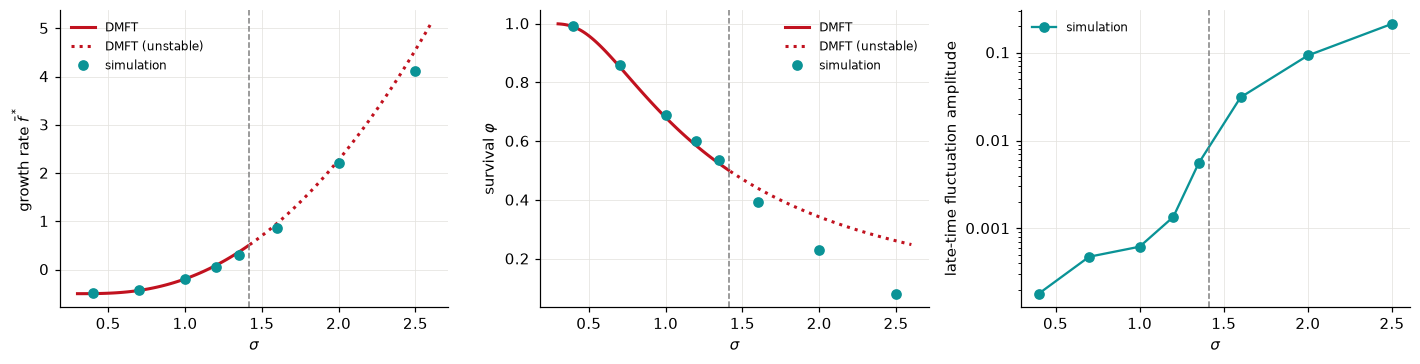

In [3]:
d = np.load(DATA / "dmft_validation.npz")
sg = np.linspace(0.3, 2.6, 200)
fp = [regular_fixed_point(0.5, s) for s in sg]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, (key, lab) in enumerate((("gstar", r"growth rate $\bar f^*$"), ("phi", r"survival $\varphi$"))):
    y = np.array([f[key] for f in fp])
    ax[k].plot(sg[sg < np.sqrt(2)], y[sg < np.sqrt(2)], color="#c1121f", lw=2, label="DMFT")
    ax[k].plot(sg[sg >= np.sqrt(2)], y[sg >= np.sqrt(2)], ":", color="#c1121f", lw=2, label="DMFT (unstable)")
    ax[k].plot(d["sigmas"], d["sim"][:, k], "o", color="#0a9396", label="simulation")
    ax[k].set(xlabel=r"$\sigma$", ylabel=lab)
ax[2].plot(d["sigmas"], d["sim"][:, 2], "o-", color="#0a9396", label="simulation")
ax[2].set(xlabel=r"$\sigma$", ylabel="late-time fluctuation amplitude", yscale="log")
for a in ax:
    a.axvline(np.sqrt(2), color="grey", ls="--", lw=1)
    a.legend(frameon=False, fontsize=8)
    tidy(a)
plt.tight_layout()
print("mu independence at sigma = 1 (mu = 0, -1, -2):")
for m, row in zip(d["mui_mus"], d["mui"]):
    print(f"  mu {0 - m:+.0f}: growth {row[0]:+.3f} (theory {regular_fixed_point(m, 1.0)['gstar']:+.3f}), survival {row[1]:.3f}")

Below $\sigma_c$ growth rate and survival agree to one or two per cent with nothing fitted, and the fluctuation
amplitude switches on at $\sqrt2$. Beyond it the static solution overshoots, since it is unstable there.

## Heterogeneous graphs: the stability line in closed form

For the bilinear kernel $K_{pr}=\rho_r\kappa_p\kappa_r$ the stability operator has rank one, and the threshold is

$$\sigma_c^{-2}=\big\langle\kappa^2\Phi_{\mathcal N}(\Delta_\kappa)\big\rangle,\qquad \Delta_\kappa=A\kappa^{-1/2}+M\kappa^{1/2},\qquad
\big\langle\kappa^2\Delta_\kappa w_1(\Delta_\kappa)\big\rangle=0,\qquad M=\mu\big\langle\kappa^{3/2}w_1(\Delta_\kappa)\big\rangle .$$

*Derivation.* $\Delta_\kappa=(a+\mu\kappa\bar B)/(\sigma\sqrt{\kappa Q})$ has the stated form with $A=a/\sigma\sqrt Q$ and
$M=\mu\bar B/\sigma\sqrt Q$; the $\bar B$ equation gives the relation for $M$. The second-moment equation is
$\sigma^2\langle\kappa^2w_2\rangle=1$ and the Perron root is $\sigma^2\langle\kappa^2w_0\rangle$; equating them and using
$w_2-w_0=\Delta w_1$ gives the first relation. Writing $\kappa=1+\epsilon$ and expanding to second order
($\Delta\equiv0$ and $M_0=\mu/\sqrt{2\pi}$ on the regular graph) gives, to first order in the degree variance,

$$\boxed{\sigma_c\simeq\sqrt2\Big[1-\frac{\operatorname{Var}\kappa}{2}\Big(1-\frac{\mu^2}{2\pi}\Big)\Big].}$$

Degree heterogeneity lowers the threshold because hubs feel a field of amplitude $\propto\sqrt\kappa$; a mean
interaction of either sign raises it, and beyond first order competition raises it most, because it removes the
hubs, which are the noisiest firms.

In [4]:
def sigma_c_bilinear(mu, k):
    """Exact threshold for the bilinear kernel on the node degrees k (lambda = 0, gamma = 0); mu in paper sign."""
    k = k / k.mean()
    m0 = 1 / np.sqrt(2 * np.pi)
    def eqs(x):
        A, M = x
        D = A / np.sqrt(k) + M * np.sqrt(k)
        return [np.mean(k ** 2 * D * w1(D)), M - mu * np.mean(k ** 1.5 * w1(D))]
    A, M = fsolve(eqs, [-mu * m0, mu * m0], xtol=1e-12)
    D = A / np.sqrt(k) + M * np.sqrt(k)
    return np.mean(k ** 2 * norm.cdf(D)) ** -0.5


def sigma_c_first_order(mu, k):
    return np.sqrt(2) * (1 - np.var(k / k.mean()) / 2 * (1 - mu ** 2 / (2 * np.pi)))


def sigma_c_hdmft(mu, k, kernel="scm"):
    w, K, c, cl = classes(k)
    if kernel == "bilinear":
        v = cl["degree_fractions"]
        K = np.outer(v, v) / (w @ v)
        if K.max() > 1:
            return np.nan                                  # not a probability: structural cutoff
    return heterogeneous_sigma_c(-mu, w, K, c, lam=0.0, bracket=(0.3, 3.0))


print(f"{'':10} {'mu':>5} {'1st order':>9} {'exact bil.':>10} {'HDMFT bil.':>10} {'HDMFT SCM':>9}")
for alpha in (6.0, 3.5):
    k = degrees(alpha)
    print(f"alpha {alpha}, Var kappa {np.var(k / k.mean()):.2f}")
    for mu in (1.0, 0.0, -1.0, -2.0):
        print(f"{'':10} {mu:+5.1f} {sigma_c_first_order(mu, k):9.3f} {sigma_c_bilinear(mu, k):10.3f} "
              f"{sigma_c_hdmft(mu, k, 'bilinear'):10.3f} {sigma_c_hdmft(mu, k):9.3f}")

              mu 1st order exact bil. HDMFT bil. HDMFT SCM


alpha 6.0, Var kappa 0.06


            +1.0     1.377      1.386      1.385     1.385


            +0.0     1.370      1.372      1.374     1.375


            -1.0     1.377      1.383      1.384     1.384


...

alpha 3.5, Var kappa 0.45


            +1.0     1.145      1.323      1.294     1.288


            +0.0     1.095      1.174      1.201     1.211


            -1.0     1.145      1.288      1.286     1.290


            -2.0     1.298      1.421      1.414     1.417


The exact relation agrees with the 60-class HDMFT to $0.002$ at $\alpha=6$ and $0.03$ at $\alpha=3.5$ (binning
smooths the hub tail); first order is good only for light tails. At $\alpha=2.5$ the bilinear kernel is not a
probability, and only the soft-configuration HDMFT applies.

**Zero growth.** Since $\bar f^*=1-a$, the zero-growth line is $a=1$ with $\mu$ as the unknown. In the one-class
limit $\mu^{(0)}=-g_0(\sigma)$. For the bilinear kernel, expanding as above,
$\mu^{(0)}(\sigma)\simeq-g_0(\sigma)+c(\sigma)\operatorname{Var}\kappa$ with $c(\sigma\to0)=0$ and
$c(\sigma\to\sqrt2)=\tfrac54-\tfrac\pi2\simeq-0.32$: at most a third of the shift of $\sigma_c$, which is why the
zero-growth lines of different graphs nearly coincide.

In [5]:
def zero_growth_first_order(sig, v):
    """Regular-graph line mu0(sigma), its first-order shift in Var kappa = v, and the coefficient c(sigma)."""
    D = brentq(lambda d: sig * sig * w2(d) - 1, -20, 60)
    mu = D / w1(D) - 1
    W0, W1, W2, P = w0(D), w1(D), w2(D), phi(D)
    c1, c2 = (mu - 1) * W1 / 2, (3 - mu) * W1 / 8
    Y = 4 * c1 * W1 + 2 * c2 * W1 + c1 ** 2 * W0 + W2
    dD = -v * Y / (2 * W1)
    X = (1 + mu) * (c2 * W0 + c1 ** 2 * P / 2) + c1 * W0 * (1 + 3 * mu) / 2 + W1 * (3 * mu - 1) / 8
    dmu = (dD * (1 - (1 + mu) * W0) - v * X) / W1
    return mu, mu + dmu, dmu / v


def zero_growth_exact(sig, k):
    k = k / k.mean()
    D0, mu0 = brentq(lambda d: sig * sig * w2(d) - 1, -20, 60), None
    mu0 = D0 / w1(D0) - 1
    def eqs(x):
        A, M, mu = x
        D = A / np.sqrt(k) + M * np.sqrt(k)
        return [sig ** 2 * np.mean(k ** 2 * w2(D)) - 1, M - mu * np.mean(k ** 1.5 * w1(D)), A - np.mean(np.sqrt(k) * w1(D))]
    return fsolve(eqs, [w1(D0), mu0 * w1(D0), mu0], xtol=1e-12)[2]


k6 = degrees(6.0)
print(f"alpha 6 (Var kappa {np.var(k6 / k6.mean()):.3f}):  sigma  regular  first order   c(sigma)  exact bilinear")
for s in (0.6, 0.8, 1.0, 1.2, 1.35):
    m0, m1, c = zero_growth_first_order(s, np.var(k6 / k6.mean()))
    print(f"{'':30} {s:.2f}  {m0:+.4f}  {m1:+.4f}   {c:+.3f}    {zero_growth_exact(s, k6):+.4f}")
print(f"c(sigma -> sqrt 2) = 5/4 - pi/2 = {5 / 4 - np.pi / 2:.3f}")

alpha 6 (Var kappa 0.062):  sigma  regular  first order   c(sigma)  exact bilinear
                               0.60  -0.0297  -0.0320   -0.036    -0.0316
                               0.80  -0.1238  -0.1289   -0.083    -0.1283
                               1.00  -0.3055  -0.3150   -0.153    -0.3139
                               1.20  -0.5852  -0.5999   -0.236    -0.5976
                               1.35  -0.8629  -0.8814   -0.297    -0.8777
c(sigma -> sqrt 2) = 5/4 - pi/2 = -0.321


## The deterministic phase diagram

Panel (a): $\alpha=2.5$, $N=4000$, $C=100$, $\lambda=10^{-3}$. Below the stability line (60 classes, SCM kernel) the
composition has a unique fixed point; above it chaos coexists with trapping equilibria. The zero-growth line
(white; dashed where it continues an unstable fixed point, i.e. is not controlled) separates growing from
shrinking economies. Symbols are simulation: zero crossings of the median growth rate, the $\sigma$ above which the
median churn exceeds $0.035$ (the old "freezing line" of the thesis), and cells whose integration failed (a
numerical artefact: the immigration floor falls below the solver tolerance at strong growth).

Panel (b): heavier degree tails lower $\sigma_c$ at weak competition and make it rise faster with competition,
so the lines cross near $\mu\simeq-1.5$: competition removes the hubs, which are the source of the instability.

Panel (c): above the line, frozen and chaotic runs coexist. For ten graphs per point, each with its own HDMFT
$\sigma_c$, a run is chaotic if the fluctuation amplitude persists to $T=1600$. At $\sigma_c$ no run is chaotic;
chaos takes over within $0.1$ at strong competition and $0.2$ at weak. The thesis' freezing line is a majority
contour of this coexistence region at $N=4000$, $T=400$, not a second transition.

The theory lines and the coexistence runs are cached in `data/`; the functions below regenerate them
(minutes for the lines, about an hour for the coexistence runs). The simulated grid
`phase_meandeg_fine_24x20_10s.npz` comes from the thesis and has no generator here.

In [6]:
def phase_theory_lines(path=DATA / "phase_theory_lines.npz"):
    """sigma_c(mu) for alpha 2.2-6 (lambda 0, and 1e-3 at alpha 2.5) and the zero-growth line, 60 SCM classes."""
    if not path.exists():
        from joblib import Parallel, delayed
        alphas, mus, sigmas = (2.2, 2.5, 3.5, 6.0), np.linspace(0.0, 2.5, 41), np.linspace(0.4, 1.95, 32)
        def sc(alpha, mu, lam=0.0):
            w, K, c, _ = classes(degrees(alpha))
            try:
                return heterogeneous_sigma_c(mu, w, K, c, lam=lam, bracket=(0.3, 3.0))
            except Exception:
                return np.nan
        def zg(alpha, s):
            w, K, c, _ = classes(degrees(alpha))
            try:
                m, ok = heterogeneous_zero_growth(s, w, K, c, lam=0.0, bracket=(0.0, 6.0))
                return -m, float(ok)
            except Exception:
                return np.nan, np.nan
        SC = np.array(Parallel(n_jobs=-1)(delayed(sc)(a, m) for a in alphas for m in mus)).reshape(len(alphas), -1)
        Z = np.array(Parallel(n_jobs=-1)(delayed(zg)(a, s) for a in alphas for s in sigmas)).reshape(len(alphas), -1, 2)
        SC25 = np.array(Parallel(n_jobs=-1)(delayed(sc)(2.5, m, 1e-3) for m in mus))
        np.savez(path, alphas=alphas, mus=mus, sigmas=sigmas, sigma_c=SC, mu0=Z[..., 0], controlled=Z[..., 1],
                 sigma_c_a25_lam1e3=SC25)
    return np.load(path)


def zero_growth_line(path=DATA / "zero_growth_line.npz"):
    """HDMFT g* = 0 contour on one alpha = 2.5 graph of the simulated grid, against the grid's zero crossings."""
    if not path.exists():
        grid = np.load(DATA / "phase_meandeg_fine_24x20_10s.npz")
        n = int(grid["N"])
        k = np.diff(powerlaw_coupling(n, 0.0, 1.0, alpha=2.5, mean_degree=n // 40, seed=0).indptr)
        w, K, c, _ = classes(k, 30)
        sig = np.unique(np.concatenate([np.linspace(0.35, 1.25, 25), grid["sigmas"]]))
        th = [heterogeneous_zero_growth(x, w, K, c) for x in sig]
        g = np.nanmedian(grid["raw"], axis=2)[..., 1]
        obs = np.full(grid["sigmas"].shape, np.nan)
        for i, row in enumerate(g):
            b = np.where(np.isfinite(row[:-1]) & np.isfinite(row[1:]) & (row[:-1] * row[1:] <= 0))[0]
            if b.size:
                j = b[0]
                obs[i] = grid["mus"][j] - row[j] * (grid["mus"][j + 1] - grid["mus"][j]) / (row[j + 1] - row[j])
        ok = np.isfinite(obs)
        np.savez(path, sigma=sig, mu_thesis=-np.array([t[0] for t in th]), controlled=np.array([t[1] for t in th]),
                 measured_sigma=grid["sigmas"][ok], measured_mu_thesis=-obs[ok])
    return np.load(path)


def coexistence(path=DATA / "phase_coexistence.npz"):
    """Ten alpha = 2.5 graphs (N 4000, C 100, lambda 1e-3) at sigma_c + ds: amplitude of ln S in [600, 800], [1400, 1600]."""
    if not path.exists():
        from joblib import Parallel, delayed
        from scipy.integrate import solve_ivp
        N, C, LAM, MUS, DS = 4000, 100, 1e-3, (1.97, 1.05), (0.0, 0.025, 0.05, 0.1, 0.2)
        def sc(mu, seed):
            w, K, c, _ = classes(degrees(2.5, seed=seed))
            return heterogeneous_sigma_c(mu, w, K, c, lam=LAM, bracket=(0.8, 2.0))
        def amp(lnS):
            big = (lnS > np.log(0.1)).all(1)
            return float(np.median(lnS[big].std(1))) if big.any() else np.nan
        def run(mu, seed, sigma):
            a = powerlaw_coupling(N, mu, sigma, alpha=2.5, mean_degree=C, seed=seed)
            w0_ = np.random.default_rng(seed).uniform(0.5, 1.5, N)
            def rhs(t, s):
                w = np.clip(s, 0.0, None); w = w / w.sum()
                f = 1.0 - N * w - N * (a @ w)
                return w * (f - w @ f) + LAM * (1.0 / N - w)
            te = np.concatenate([np.arange(600, 800, 0.5), np.arange(1400, 1600, 0.5)])
            r = solve_ivp(rhs, (0.0, 1600.0), w0_ / w0_.sum(), t_eval=te, rtol=1e-4, atol=1e-7)
            lnS = np.log(np.clip(r.y * N, 1e-2, None))
            k = np.searchsorted(r.t, 1400.0)
            return amp(lnS[:, :k]), amp(lnS[:, k:])
        keys = [(m, s) for m in MUS for s in range(10)]
        SC = dict(zip(keys, Parallel(n_jobs=-1)(delayed(sc)(m, s) for m, s in keys)))
        R = Parallel(n_jobs=-1)(delayed(run)(m, s, SC[(m, s)] + dd) for m, s in keys for dd in DS)
        np.savez(path, mus=MUS, ds=DS, sigma_c=np.array([[SC[(m, s)] for s in range(10)] for m in MUS]),
                 amp=np.array(R).reshape(len(MUS), 10, len(DS), 2))
    return np.load(path)

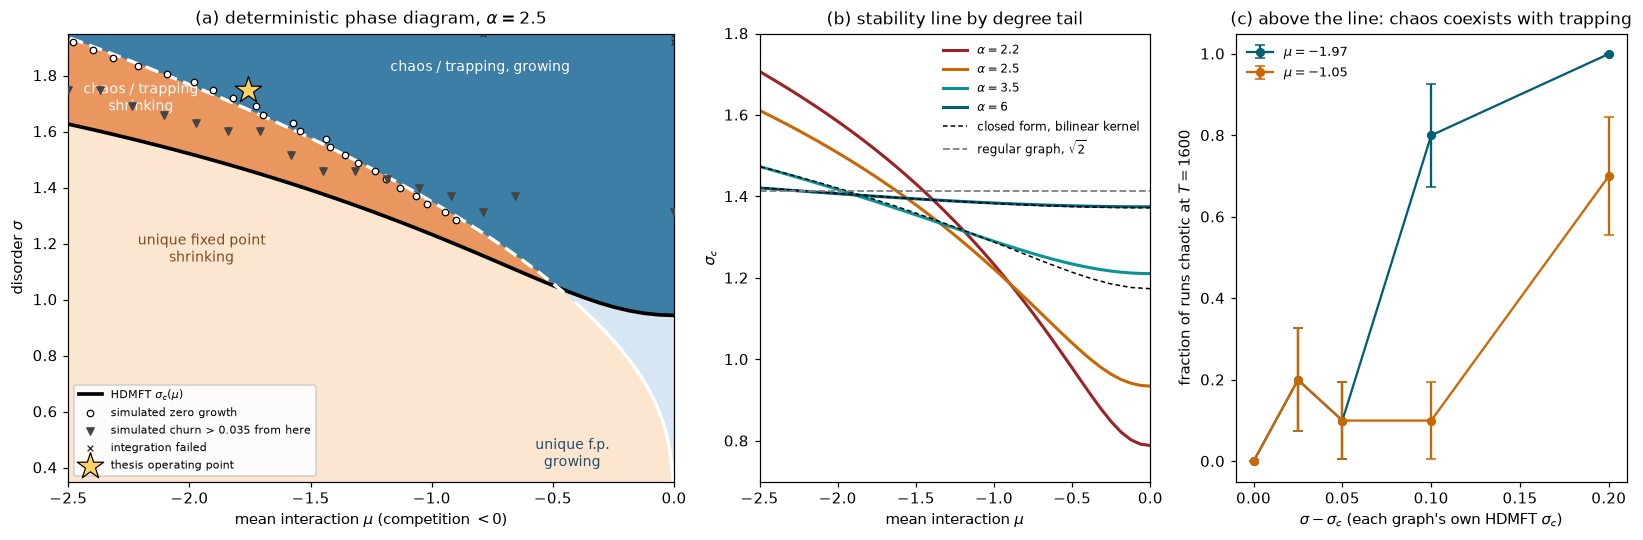

In [7]:
from matplotlib.colors import ListedColormap
fam, zg, coex = phase_theory_lines(), zero_growth_line(), coexistence()
grid = np.load(DATA / "phase_meandeg_fine_24x20_10s.npz")
fig = plt.figure(figsize=(15, 5.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.55, 1, 1])
ax = fig.add_subplot(gs[0])
o = np.argsort(-fam["mus"])
mu_sc, s_sc = -fam["mus"][o], fam["sigma_c_a25_lam1e3"][o]
oz = np.argsort(zg["sigma"])
s_z, mu_z = zg["sigma"][oz], zg["mu_thesis"][oz]
mu, sg = np.linspace(-2.5, 0.0, 600), np.linspace(0.35, 1.95, 500)
M, Sg = np.meshgrid(mu, sg)
region = 2 * (Sg > np.interp(M, mu_sc, s_sc)) + (M > np.interp(Sg, s_z, mu_z))
ax.pcolormesh(mu, sg, region, cmap=ListedColormap(["#fde6cf", "#d6e6f2", "#e9965f", "#3d7ea6"]),
              vmin=-0.5, vmax=3.5, shading="auto", rasterized=True)
ax.plot(mu_sc, s_sc, color="black", lw=2.4, label=r"HDMFT $\sigma_c(\mu)$")
c = zg["controlled"][oz].astype(bool)
ax.plot(mu_z[c], s_z[c], color="white", lw=2.2)
ax.plot(mu_z[~c], s_z[~c], color="white", lw=2.2, ls=(0, (4, 2)))
ax.scatter(zg["measured_mu_thesis"], zg["measured_sigma"], s=18, facecolor="white", edgecolor="black", lw=0.8,
           zorder=5, label=r"simulated zero growth")
gsig, gmu, raw = grid["sigmas"], -grid["mus"], grid["raw"]
og = np.argsort(gmu)
with np.errstate(all="ignore"):
    churn = np.nanmedian(raw[..., 0], 2)[:, og]
fail = np.isfinite(raw[..., 0]).mean(2)[:, og] < 0.5
churn = np.where(fail, 1.0, churn)
first = np.array([gsig[np.argmax(col >= 0.035)] if (col >= 0.035).any() else np.nan for col in churn.T])
edge = first <= gsig[0] + 1e-9
ax.scatter(gmu[og][~edge], first[~edge], marker="v", s=22, color="#444444", zorder=5, label="simulated churn > 0.035 from here")
fm, fs = np.meshgrid(gmu[og], gsig)
ax.scatter(fm[fail], fs[fail], marker="x", s=14, color="#222222", lw=0.8, zorder=4, label="integration failed")
ax.scatter([-1.76], [1.75], marker="*", s=330, color="#ffd166", edgecolor="black", lw=0.8, zorder=6, label="thesis operating point")
for x, y, txt, col in ((-1.95, 1.18, "unique fixed point\nshrinking", "#7a4a1f"), (-0.42, 0.45, "unique f.p.\ngrowing", "#1d4e6e"),
                       (-2.2, 1.72, "chaos / trapping\nshrinking", "white"), (-0.8, 1.83, "chaos / trapping, growing", "white")):
    ax.text(x, y, txt, color=col, fontsize=9, ha="center", va="center")
ax.set(xlim=(-2.5, 0), ylim=(0.35, 1.95), xlabel=r"mean interaction $\mu$ (competition $<0$)", ylabel=r"disorder $\sigma$",
       title=r"(a) deterministic phase diagram, $\alpha=2.5$")
ax.legend(loc="lower left", fontsize=7.5, framealpha=0.92)
ax = fig.add_subplot(gs[1])
cols = {2.2: "#9b2226", 2.5: "#ca6702", 3.5: "#0a9396", 6.0: "#005f73"}
for i, al in enumerate(fam["alphas"]):
    al = float(al)
    ax.plot(-fam["mus"], fam["sigma_c"][i], color=cols[al], lw=2, label=rf"$\alpha={al:g}$")
    if al >= 3.5:
        mus = np.linspace(0.0, -2.5, 21)
        k = degrees(al)
        ax.plot(mus, [sigma_c_bilinear(m, k) for m in mus], color="black", lw=1, ls=(0, (3, 2)))
ax.plot([], [], color="black", lw=1, ls=(0, (3, 2)), label="closed form, bilinear kernel")
ax.axhline(np.sqrt(2), color="grey", ls="--", lw=1.2, label=r"regular graph, $\sqrt{2}$")
ax.set(xlim=(-2.5, 0), ylim=(0.7, 1.8), xlabel=r"mean interaction $\mu$", ylabel=r"$\sigma_c$", title="(b) stability line by degree tail")
ax.legend(fontsize=8, frameon=False)
ax = fig.add_subplot(gs[2])
A, ds = coex["amp"], np.array(coex["ds"])
for i, (m, col) in enumerate(zip(coex["mus"], ("#005f73", "#ca6702"))):
    chaos = (A[i, :, :, 1] >= 1e-2).mean(0)
    ax.errorbar(ds, chaos, yerr=np.sqrt(chaos * (1 - chaos) / A.shape[1]), color=col, marker="o", ms=5, capsize=3,
                label=rf"$\mu={-m:.2f}$")
ax.set(xlabel=r"$\sigma-\sigma_c$ (each graph's own HDMFT $\sigma_c$)", ylabel="fraction of runs chaotic at $T=1600$",
       ylim=(-0.05, 1.05), title="(c) above the line: chaos coexists with trapping")
ax.legend(fontsize=8.5, frameon=False)
plt.tight_layout()

The zero-growth line leaves the stable region near $(\mu,\sigma)=(-0.45,1.02)$ and every simulated point lies above
it. Its continuation through the unstable regime nonetheless tracks the simulated contour (mean absolute error
$\approx0.03$ in $\mu$); above $\sigma\simeq1.02$ this is an empirically successful continuation, not a derivation.

## Demographic noise: one node at constant field

At constant $\Phi$, $dS=S(\Phi-S)dt+\sqrt{DS}\,dW$ is a diffusion absorbed at $0$, with scale density
$s'(y)=\exp[-(2/D)(\Phi y-y^2/2)]$ and speed density $m(y)=2/(Dy\,s'(y))$. A newborn reaches its plateau before
exiting with probability

$$P_{\rm est}=\frac{\int_0^Ds'(y)\,dy}{\int_0^\Phi s'(y)\,dy},\qquad\text{and the mean time to exit is}\qquad
T(S_0)=2\int_0^{S_0}s'(y)\int_y^\infty\frac{dz}{Dz\,s'(z)}\,dy .$$

For $\Phi\le0$, $T$ is of order $1/|\Phi|$ and, for a newborn, independent of $D$ (near zero the logistic term is
negligible and the Feller survival probability from $S_0=D$ does not contain $D$). For $\Phi>0$ it grows as
$e^{\Phi^2/D}$: **an established firm exits through dips of its field, not through noise.**

In [8]:
D, dt = 0.1, 0.002
rng = np.random.default_rng(1)
sp = lambda y, P: np.exp(-(2 / D) * (P * y - y * y / 2))
p_hit = lambda x0, h, P: quad(sp, 0, x0, args=(P,))[0] / quad(sp, 0, h, args=(P,))[0]


def T_exit(x0, P):
    inner = lambda y: quad(lambda z: 1 / (D * z * sp(z, P)), y, P + 10 * np.sqrt(D) + 1, limit=200)[0]
    return 2 * quad(lambda y: sp(y, P) * inner(y), 0, x0, limit=200)[0]


print("establishment, P(reach Phi before 0 | S0 = D):")
for P in (0.2, 0.6, 1.0):
    n = 20000
    S, done, hit = np.full(n, D), np.zeros(n, bool), np.zeros(n, bool)
    while not done.all():
        s = S[~done]
        S[~done] = s + s * (P - s) * dt + np.sqrt(D * np.maximum(s, 0) * dt) * rng.standard_normal(s.size)
        hit |= (~done) & (S >= P)
        done |= (S >= P) | (S <= 0)
    print(f"   Phi {P:.1f}: simulation {hit.mean():.3f}   exact {p_hit(D, P, P):.3f}   (linear Feller 1 - e^-2Phi {1 - np.exp(-2 * P):.3f})")
print("mean time to exit:")
for P, x0 in ((0.0, D), (-0.5, D), (0.3, 0.3), (0.5, 0.5)):
    n = 4000 if P > 0 else 20000
    S, t, alive = np.full(n, x0), np.zeros(n), np.ones(n, bool)
    while alive.any() and t.max() < 2000:
        s = S[alive]
        S[alive] = s + s * (P - s) * dt + np.sqrt(D * np.maximum(s, 0) * dt) * rng.standard_normal(s.size)
        t[alive] += dt
        alive &= S > 0
    print(f"   Phi {P:+.1f} from S0 = {x0:.2f}: simulation {t.mean():6.2f}   exact {T_exit(x0, P):6.2f}")

establishment, P(reach Phi before 0 | S0 = D):


   Phi 0.2: simulation 0.548   exact 0.551   (linear Feller 1 - e^-2Phi 0.330)


   Phi 0.6: simulation 0.582   exact 0.583   (linear Feller 1 - e^-2Phi 0.699)


   Phi 1.0: simulation 0.833   exact 0.831   (linear Feller 1 - e^-2Phi 0.865)
mean time to exit:


   Phi +0.0 from S0 = 0.10: simulation   3.89   exact   3.84


   Phi -0.5 from S0 = 0.10: simulation   2.15   exact   2.16


   Phi +0.3 from S0 = 0.30: simulation  13.53   exact  13.18


   Phi +0.5 from S0 = 0.50: simulation  38.75   exact  38.01


**Renewal law.** With turnover, the lives at a node of constant field are independent and identically distributed.
By the renewal–reward theorem the fraction of time spent near $x$ is the expected time one life spends there, the
Green's function $G(D,x)=s(\min(x,D))\,m(x)$, divided by the mean life:

$$p(x\mid h)=\frac{s(\min(x,D))\,m(x)}{T(D)},\qquad T(D)=\int_0^\infty s(\min(x,D))\,m(x)\,dx,$$

with turnover rate $1/T(D)$. The law has two parts: a Gaussian plateau of variance $D/2$ around $h$, and below $D$ a
nearly flat density of newborns drifting to exit. Against direct simulation of one node:

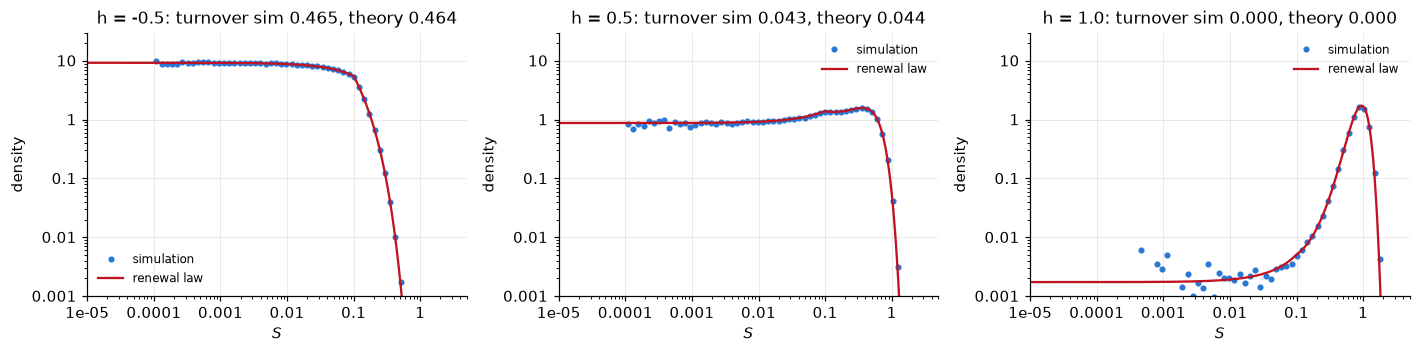

In [9]:
def renewal_density(h, D, x):
    """p(x | h) on the grid x (fine near 0), normalised numerically."""
    y = np.concatenate([[0.0], x])
    sprime = np.exp(-(2 / D) * (h * y - y * y / 2))
    s = cumulative_trapezoid(sprime, y, initial=0.0)[1:]
    sD = np.interp(D, x, s)
    G = np.minimum(s, sD) * 2 / (D * x * sprime[1:])
    T = np.trapezoid(G, x)
    return G / T, T


x = np.concatenate([np.geomspace(1e-6, D, 400), np.linspace(D, 4, 2000)[1:]])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for a, h in zip(ax, (-0.5, 0.5, 1.0)):
    n, S, dt_ = 4000, np.full(4000, D), 0.002
    samples, exits = [], 0
    for step in range(int(300 / dt_)):
        S = S + S * (h - S) * dt_ + np.sqrt(D * np.maximum(S, 0) * dt_) * rng.standard_normal(n)
        dead = S <= 0
        exits += dead.sum() if step * dt_ > 50 else 0
        S[dead] = D
        if step * dt_ > 50 and step % 250 == 0:
            samples.append(S.copy())
    samples = np.concatenate(samples)
    p, T = renewal_density(h, D, x)
    bins = np.geomspace(1e-4, 4, 60)
    hist, e = np.histogram(samples, bins, density=True)
    a.loglog(np.sqrt(e[1:] * e[:-1]), hist, "o", ms=3, color="#2a78d6", label="simulation")
    a.loglog(x, p, color="#c1121f", lw=1.5, label="renewal law")
    a.set(xlabel="$S$", ylabel="density", ylim=(1e-3, 30), xlim=(1e-5, 5),
          title=f"h = {h}: turnover sim {exits / n / 250:.3f}, theory {1 / T:.3f}")
    a.legend(frameon=False, fontsize=8)
    tidy(a)
plt.tight_layout()

## The instability line with noise

When the field is static, each node follows the renewal law at its $h=a+\mu B_p+\sigma\sqrt{q_p}z$, and the static
self-consistency reads $B_p=\sum_rK_{pr}\mathbb E\langle S\rangle_{h_r}$, $q_p=\sum_rK_{pr}\mathbb E\langle S\rangle_{h_r}^2$,
$\sum_p\rho_p\mathbb E\langle S\rangle_{h_p}=1$. Stability is the Perron condition with the
susceptibility $\chi=\partial\langle S\rangle_h/\partial h$ in place of the survival step: the static state is stable
while the Perron root of $\sigma^2\,{\rm diag}(\mathbb E\chi^2)\,K$ is below one. Noise smooths $\chi$ and raises the line
almost linearly with $D$; as $D\to0$ it tends to the deterministic line ($\sqrt2$ on the complete graph). The same
theory predicts the turnover rate to $0.5\%$ below $\sigma_c$ and $1.5\%$ above it. Turnover is set by the nodes with
$h<0$, where a newborn's life does not depend on $D$. The static closure underestimates the share of the field
variance that moves in time by a factor 2–3 below $\sigma_c$, because it omits the collective amplification of slow
field fluctuations, which needs a two-time theory with noise (open).

**The solver.** $\langle S\rangle_h$, $\langle S^2\rangle_h$ and $\ln T(h)$ are tabulated once per $D$ on a grid of fields (quadratures in logs, with a
log grid below $D$ to resolve the flicker scale $D/|h|$), and $\chi=\partial\langle S\rangle_h/\partial h$ by differentiation. The closure is
iterated with damping on $(B_p,q_p)$, solving the normalisation for $a$ at each step.

In [10]:
Z = np.linspace(-8.0, 8.0, 801)
WZ = np.exp(-Z ** 2 / 2) * (Z[1] - Z[0]) / np.sqrt(2 * np.pi)
_tables, _warm = {}, {}


def renewal_moments(h, D, n_lo=1500, n_hi=6000):
    """<S>, <S^2> and log T of the renewal law at fields h."""
    h = np.atleast_1d(np.asarray(h, float))
    x_lo = np.geomspace(1e-10 * D, D, n_lo)
    x = np.concatenate([x_lo, np.linspace(D, max(h.max(), 0.0) + 12 * np.sqrt(D) + 2.0, n_hi)[1:]])
    f = np.exp(-(2 / D) * (h[:, None] * x_lo[None, :] - x_lo ** 2 / 2))          # s'(y) on [0, D]
    s_lo = x_lo[0] * f[:, :1] + np.concatenate(
        [np.zeros((h.size, 1)), np.cumsum(0.5 * (f[:, 1:] + f[:, :-1]) * np.diff(x_lo), axis=1)], axis=1)
    s_min = np.concatenate([s_lo, np.repeat(s_lo[:, -1:], x.size - n_lo, axis=1)], axis=1)
    logG = np.log(s_min) + np.log(2 / (D * x))[None, :] + (2 / D) * (h[:, None] * x[None, :] - x ** 2 / 2)
    top = logG.max(1, keepdims=True)
    G = np.exp(logG - top)
    T = np.trapezoid(G, x, axis=1)
    return np.trapezoid(G * x, x, axis=1) / T, np.trapezoid(G * x ** 2, x, axis=1) / T, np.log(T) + top[:, 0]


def renewal_table(D):
    if D not in _tables:
        hs = np.concatenate([np.linspace(-300, -20, 400)[:-1], np.linspace(-20, -5, 300)[:-1], np.linspace(-5, 25, 3000)])
        parts = [renewal_moments(hs[i:i + 100], D, n_hi=6000 if D >= 1e-2 else 20000) for i in range(0, hs.size, 100)]
        mean, second, logT = (np.concatenate([p[k] for p in parts]) for k in range(3))
        _tables[D] = (hs, mean, second, np.gradient(mean, hs), logT)
    return _tables[D]


def solve_renewal_fixed_point(mu, sigma, w, Kc, D, iters=3000, tol=1e-10):
    """Static closure with the renewal law (code sign mu > 0 competition); Kc = kernel * weights / connectance."""
    hs, tm, ts, tc, tl = renewal_table(D)
    B, q = _warm.get((D, w.size), (Kc.sum(1), Kc.sum(1)))

    def stats(B, q, a):
        h = a - mu * B[:, None] + sigma * np.sqrt(q)[:, None] * Z[None, :]
        m = np.interp(h, hs, tm)
        return m @ WZ, (m ** 2) @ WZ, h

    def a_of(B, q):
        return brentq(lambda a: w @ stats(B, q, a)[0] - 1.0, -50.0, 50.0 + mu * B.max(), xtol=1e-12)

    for _ in range(iters):
        mean, Q, _ = stats(B, q, a_of(B, q))
        B_new, q_new = Kc @ mean, Kc @ Q
        err = max(np.max(np.abs(B_new - B)), np.max(np.abs(np.log(q_new / q))))
        B, q = 0.5 * (B + B_new), np.sqrt(q * q_new)
        if err < tol:
            break
    _warm[(D, w.size)] = (B.copy(), q.copy())
    a = a_of(B, q)
    mean, Q, h = stats(B, q, a)
    chi2 = (np.interp(h, hs, tc) ** 2) @ WZ
    temporal = sigma ** 2 * (Kc @ (np.interp(h, hs, ts) @ WZ - Q))        # field variance from size fluctuations
    centre = a - mu * B
    total = w @ (sigma ** 2 * (Kc @ (np.interp(h, hs, ts) @ WZ)) + (centre - w @ centre) ** 2)
    return dict(growth_rate=float(1.0 - a), stability_radius=float(np.max(np.abs(np.linalg.eigvals(sigma ** 2 * chi2[:, None] * Kc)))),
                turnover=float(w @ (np.exp(-np.interp(h, hs, tl)) @ WZ)), temporal_share=float(w @ temporal / total))


def renewal_sigma_c(mu, w, Kc, D, bracket=(0.5, 2.5)):
    return brentq(lambda s: solve_renewal_fixed_point(mu, s, w, Kc, D)["stability_radius"] - 1.0, *bracket, xtol=1e-6)


def renewal_zero_growth(mu, w, Kc, D, bracket=(0.5, 3.0)):
    return brentq(lambda s: solve_renewal_fixed_point(mu, s, w, Kc, D)["growth_rate"], *bracket, xtol=1e-6)

D: [0.003 0.01  0.03  0.05  0.1   0.15  0.2   0.3  ]
complete graph sigma_c(D): [1.413 1.416 1.428 1.439 1.466 1.493 1.519 1.571] (deterministic sqrt 2 = 1.414)
alpha 2.5: sigma_c [1.46  1.462 1.47  1.477 1.497 1.517 1.537 1.577]
           zero growth [1.701 1.702 1.705 1.709 1.718 1.727 1.736 1.755]
alpha 6.0: sigma_c [1.399 1.402 1.413 1.424 1.45  1.476 1.501 1.551]
           zero growth [1.699 1.7   1.702 1.705 1.711 1.718 1.724 1.737]

alpha 6, D 0.1, N 4000 (theory sigma_c 1.451):
  sigma  turnover sim  theory   temporal share of field variance: sim  static theory
  1.20   0.309        0.307                                    0.025  0.011
  1.30   0.368        0.368                                    0.027  0.010
  1.40   0.435        0.435                                    0.033  0.008
  1.45   0.470        0.471                                    0.040  0.008
  1.50   0.511        0.509                                    0.048  0.007
  1.60   0.598        0.588               

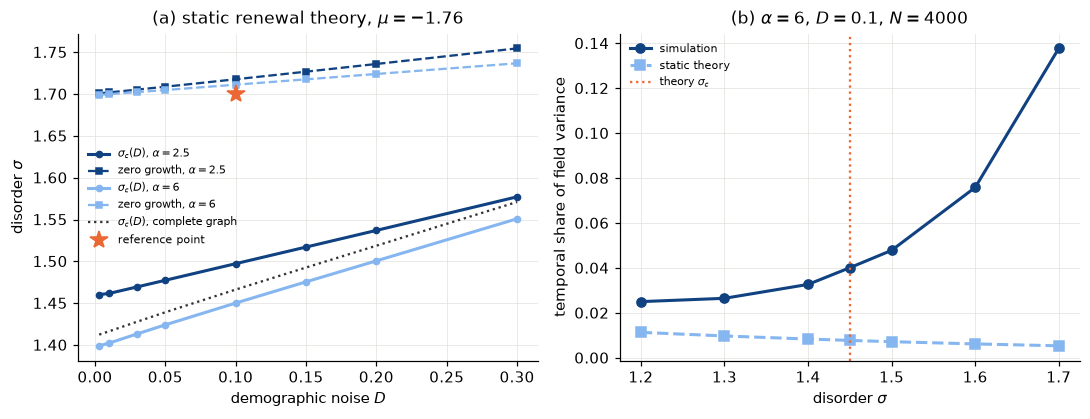

In [11]:
def demographic_classes(alpha, N, C, numpy_graph=False):
    if alpha is None:
        return np.ones(1), np.ones((1, 1))
    if numpy_graph:
        k = np.diff(configuration_coupling(N, 0.0, 1.0, alpha=alpha, mean_degree=C, seed=0).indptr)
    else:
        k = degrees(alpha, N, C)
    w, K, c, _ = classes(k)
    return w, K * w[None, :] / c


def phase_lines(path=DATA / "demographic" / "phase_lines.npz"):
    """sigma_c(D) and the zero-growth line at mu = -1.76 for alpha 2.5 and 6 and the complete graph, plus a
    simulation check at alpha 6, D 0.1, N 4000, C 100 (temporal share of the field variance, turnover)."""
    if not path.exists():
        from joblib import Parallel, delayed
        DS, SIG = np.array([0.003, 0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.3]), np.array([1.2, 1.3, 1.4, 1.45, 1.5, 1.6, 1.7])
        def lines(alpha):
            w, K = demographic_classes(alpha, 8000, 200)
            return [(renewal_sigma_c(1.76, w, K, D_), renewal_zero_growth(1.76, w, K, D_)) for D_ in DS]
        def sim(sigma, seed):
            a = powerlaw_coupling(4000, 1.76, sigma, alpha=6.0, mean_degree=100, seed=seed)
            r = integrate_demographic(a, D=0.1, tmax=500.0, t_start=200.0, dt_save=0.5, seed=seed)
            S, L = r["S"], r["life"]
            P = 1.0 - a @ S - (S * (1.0 - S - a @ S)).sum(0) / 4000
            return P.var(1).mean() / P.var(), (L[:, -1] - L[:, 0]).mean() / 300.0
        Lns = np.array(Parallel(n_jobs=2)(delayed(lines)(a) for a in (2.5, 6.0)))
        fc = np.array([renewal_sigma_c(1.76, np.ones(1), np.ones((1, 1)), D_) for D_ in DS])
        Sm = np.array(Parallel(n_jobs=-1)(delayed(sim)(s, k) for s in SIG for k in range(2))).reshape(-1, 2, 2).mean(1)
        w, K = demographic_classes(6.0, 4000, 100)
        th = [solve_renewal_fixed_point(1.76, s, w, K, 0.1) for s in SIG]
        np.savez(path, D=DS, alphas=(2.5, 6.0), sigma_c=Lns[..., 0], sigma_0=Lns[..., 1], fc_sigma_c=fc,
                 sigmas_sim=SIG, share_sim=Sm[:, 0], turnover_sim=Sm[:, 1],
                 share_th=[t["temporal_share"] for t in th], turnover_th=[t["turnover"] for t in th],
                 sigma_c_check=renewal_sigma_c(1.76, w, K, 0.1))
    return np.load(path)


pl = phase_lines()
print("D:", pl["D"])
print("complete graph sigma_c(D):", np.round(pl["fc_sigma_c"], 3), "(deterministic sqrt 2 = 1.414)")
for k, al in enumerate(pl["alphas"]):
    print(f"alpha {al}: sigma_c {np.round(pl['sigma_c'][k], 3)}\n           zero growth {np.round(pl['sigma_0'][k], 3)}")
print(f"\nalpha 6, D 0.1, N 4000 (theory sigma_c {float(pl['sigma_c_check']):.3f}):")
print("  sigma  turnover sim  theory   temporal share of field variance: sim  static theory")
for s, a, b, c, e in zip(pl["sigmas_sim"], pl["turnover_sim"], pl["turnover_th"], pl["share_sim"], pl["share_th"]):
    print(f"  {s:.2f}   {a:.3f}        {b:.3f}                                    {c:.3f}  {e:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.9))
for k, (al, c) in enumerate(zip(pl["alphas"], ("#104281", "#86b6ef"))):
    ax[0].plot(pl["D"], pl["sigma_c"][k], "o-", color=c, lw=2, ms=4, label=rf"$\sigma_c(D)$, $\alpha={al:g}$")
    ax[0].plot(pl["D"], pl["sigma_0"][k], "s--", color=c, lw=1.5, ms=4, label=rf"zero growth, $\alpha={al:g}$")
ax[0].plot(pl["D"], pl["fc_sigma_c"], ":", color="#333333", lw=1.5, label=r"$\sigma_c(D)$, complete graph")
ax[0].plot([0.1], [1.70], "*", color="#eb6834", ms=12, label="reference point")
ax[0].set(xlabel="demographic noise $D$", ylabel=r"disorder $\sigma$", title=r"(a) static renewal theory, $\mu=-1.76$")
ax[1].plot(pl["sigmas_sim"], pl["share_sim"], "o-", color="#104281", lw=2, label="simulation")
ax[1].plot(pl["sigmas_sim"], pl["share_th"], "s--", color="#86b6ef", lw=2, label="static theory")
ax[1].axvline(float(pl["sigma_c_check"]), color="#eb6834", lw=1.5, ls=":", label=r"theory $\sigma_c$")
ax[1].set(xlabel=r"disorder $\sigma$", ylabel="temporal share of field variance", title=r"(b) $\alpha=6$, $D=0.1$, $N=4000$")
for a in ax:
    a.legend(fontsize=7, frameon=False)
    tidy(a)
plt.tight_layout()
plt.savefig(FIGURES / "demographic_phase_lines.png", dpi=200)

## The phase diagram at $D=0.1$

In the plane of the mean interaction and the disorder, from the renewal theory: degree classes of the reference
graph ($\alpha=2.5$, $N=32000$, $C=200$), of an $\alpha=6$ graph, and the complete graph. On the reference graph
competition raises $\sigma_c$ strongly, because it removes the hubs, which carry the strongest fields; on the complete
graph the line does not depend on $\mu$. The zero-growth line is almost the same on the three graphs. **The reference
point, $\sigma=1.70$ against $\sigma_c(0.1)\approx1.50$, lies in the fluctuating phase**, close to the static estimate of the
zero-growth line, which is not controlled there.

alpha 2.5  sigma_c 0.827 0.887 1.005 1.126 1.236 1.334 1.420 1.497 1.565 1.626 1.681
           sigma_0 0.504 0.846 1.056 1.224 1.367 1.494 1.608 1.712 1.809 1.899 1.984
alpha 6    sigma_c 1.422 1.423 1.425 1.428 1.433 1.438 1.444 1.450 1.457 1.464 1.472
           sigma_0 0.632 0.963 1.151 1.296 1.418 1.524 1.620 1.708 1.789 1.866 1.938
complete   sigma_c 1.466 1.466 1.466 1.466 1.466 1.466 1.466 1.466 1.466 1.466 1.466
           sigma_0 0.638 0.970 1.159 1.303 1.425 1.531 1.626 1.714 1.794 1.870 1.942
mu (paper sign):     -0.00 -0.25 -0.50 -0.75 -1.00 -1.25 -1.50 -1.75 -2.00 -2.25 -2.50


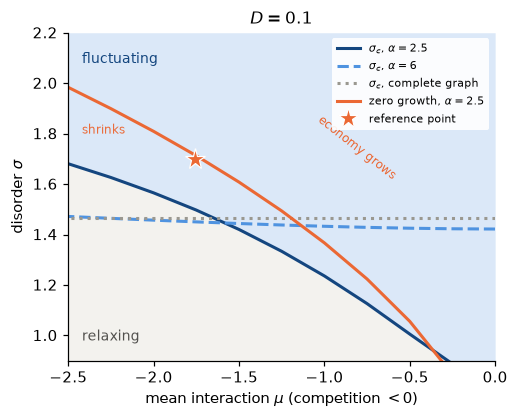

In [12]:
def phase_diagram(path=DATA / "demographic" / "phase_diagram.npz"):
    if not path.exists():
        from joblib import Parallel, delayed
        mus = np.round(np.linspace(0.0, 2.5, 11), 3)
        graphs = (("alpha 2.5", 2.5), ("alpha 6", 6.0), ("complete", None))
        def point(alpha, mu):
            w, K = demographic_classes(alpha, 32000, 200, numpy_graph=True)
            out = []
            for f in (renewal_sigma_c, renewal_zero_growth):
                try:
                    out.append(f(mu, w, K, 0.1))
                except ValueError:
                    out.append(np.nan)
            return out
        res = np.array(Parallel(n_jobs=-1)(delayed(point)(a, m) for _, a in graphs for m in mus)).reshape(3, len(mus), 2)
        np.savez(path, mus=mus, graphs=[g for g, _ in graphs], sigma_c=res[..., 0], sigma_0=res[..., 1])
    return np.load(path)


R = phase_diagram()
mu, sc, s0 = -R["mus"], R["sigma_c"], R["sigma_0"]
for g, a, b in zip(R["graphs"], sc, s0):
    print(f"{g:10s} sigma_c {' '.join(f'{x:.3f}' for x in a)}\n{'':10s} sigma_0 {' '.join(f'{x:.3f}' for x in b)}")
print("mu (paper sign):    ", " ".join(f"{x:5.2f}" for x in mu))
fig, ax = plt.subplots(figsize=(4.8, 3.9))
ax.fill_between(mu, sc[0], 2.2, color="#dbe8f8", lw=0)
ax.fill_between(mu, 0.9, sc[0], color="#f3f2ee", lw=0)
for k, (name, col, ls) in enumerate(((r"$\alpha=2.5$", "#14467f", "-"), (r"$\alpha=6$", "#4f93e0", "--"),
                                     ("complete graph", "#9a9890", ":"))):
    ax.plot(mu, sc[k], ls, color=col, lw=2, label=rf"$\sigma_c$, {name}")
ok = np.isfinite(s0[0])
ax.plot(mu[ok], s0[0][ok], "-", color="#eb6834", lw=2, label=r"zero growth, $\alpha=2.5$")
ax.plot(-1.76, 1.70, "*", color="#eb6834", ms=14, mec="white", mew=0.8, label="reference point")
ax.text(-2.42, 2.08, "fluctuating", fontsize=9, color="#14467f")
ax.text(-2.42, 0.98, "relaxing", fontsize=9, color="#52514e")
ax.text(-1.05, 1.62, "economy grows", fontsize=8, color="#eb6834", rotation=-38)
ax.text(-2.42, 1.80, "shrinks", fontsize=8, color="#eb6834")
ax.set(xlabel=r"mean interaction $\mu$ (competition $<0$)", ylabel=r"disorder $\sigma$", xlim=(mu.min(), mu.max()),
       ylim=(0.9, 2.2), title="$D=0.1$")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=True, framealpha=0.9, edgecolor="none", fontsize=7.5, loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES / "demographic_phase_diagram.png", dpi=200)